Project Description

Los Angeles, California, attracts people from all over the world, offering lots of opportunities, not always of the good kind!

In this project, you'll serve as a data detective, supporting the Los Angeles Police Department (LAPD) in analyzing crime data to guide how they should allocate resources to protect the people of their city!

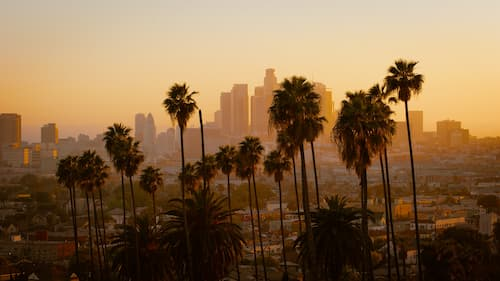

Los Angeles, California 😎. The City of Angels. Tinseltown. The Entertainment Capital of the World! 

Known for its warm weather, palm trees, sprawling coastline, and Hollywood, along with producing some of the most iconic films and songs. However, as with any highly populated city, it isn't always glamorous and there can be a large volume of crime. That's where you can help!

You have been asked to support the Los Angeles Police Department (LAPD) by analyzing crime data to identify patterns in criminal behavior. They plan to use your insights to allocate resources effectively to tackle various crimes in different areas.

## The Data

They have provided you with a single dataset to use. A summary and preview are provided below.

It is a modified version of the original data, which is publicly available from Los Angeles Open Data.

# crimes.csv

| Column     | Description              |
|------------|--------------------------|
| `'DR_NO'` | Division of Records Number: Official file number made up of a 2-digit year, area ID, and 5 digits. |
| `'Date Rptd'` | Date reported - MM/DD/YYYY. |
| `'DATE OCC'` | Date of occurrence - MM/DD/YYYY. |
| `'TIME OCC'` | In 24-hour military time. |
| `'AREA NAME'` | The 21 Geographic Areas or Patrol Divisions are also given a name designation that references a landmark or the surrounding community that it is responsible for. For example, the 77th Street Division is located at the intersection of South Broadway and 77th Street, serving neighborhoods in South Los Angeles. |
| `'Crm Cd Desc'` | Indicates the crime committed. |
| `'Vict Age'` | Victim's age in years. |
| `'Vict Sex'` | Victim's sex: `F`: Female, `M`: Male, `X`: Unknown. |
| `'Vict Descent'` | Victim's descent:<ul><li>`A` - Other Asian</li><li>`B` - Black</li><li>`C` - Chinese</li><li>`D` - Cambodian</li><li>`F` - Filipino</li><li>`G` - Guamanian</li><li>`H` - Hispanic/Latin/Mexican</li><li>`I` - American Indian/Alaskan Native</li><li>`J` - Japanese</li><li>`K` - Korean</li><li>`L` - Laotian</li><li>`O` - Other</li><li>`P` - Pacific Islander</li><li>`S` - Samoan</li><li>`U` - Hawaiian</li><li>`V` - Vietnamese</li><li>`W` - White</li><li>`X` - Unknown</li><li>`Z` - Asian Indian</li> |
| `'Weapon Desc'` | Description of the weapon used (if applicable). |
| `'Status Desc'` | Crime status. |
| `'LOCATION'` | Street address of the crime. |

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Keep chart styling consistent across the report.
sns.set_theme(style="whitegrid", context="notebook")
CHART_DIR = Path("images")
CHART_DIR.mkdir(exist_ok=True)


In [ ]:
# Load the dataset relative to this notebook/repository.
DATA_PATH = Path("crimes.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "crimes.csv was not found. Place the dataset in the repository root "
        "or update DATA_PATH to its location."
    )

crimes = pd.read_csv(DATA_PATH, low_memory=False)

print(f"Dataset shape: {crimes.shape[0]:,} rows × {crimes.shape[1]} columns")
display(crimes.head())

print("\nColumn data types:")
display(crimes.dtypes.to_frame("data_type"))

print("\nMissing values:")
missing_summary = (
    crimes.isna().sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_percent=lambda x: (x["missing_count"] / len(crimes) * 100).round(2))
    .sort_values("missing_percent", ascending=False)
)
display(missing_summary)

# Parse dates safely; invalid values become NaT and are measured below.
for date_col in ["Date Rptd", "DATE OCC"]:
    crimes[date_col] = pd.to_datetime(crimes[date_col], errors="coerce")


In [ ]:
# Validate occurrence time before extracting the hour.
time_numeric = pd.to_numeric(crimes["TIME OCC"], errors="coerce")
time_text = time_numeric.fillna(-1).astype("int64").astype(str).str.zfill(4)
hour_part = pd.to_numeric(time_text.str[-4:-2], errors="coerce")
minute_part = pd.to_numeric(time_text.str[-2:], errors="coerce")

valid_time = (
    time_numeric.notna()
    & time_numeric.between(0, 2359)
    & hour_part.between(0, 23)
    & minute_part.between(0, 59)
)

print(f"Rows in source dataset: {len(crimes):,}")
print(f"Rows with valid occurrence time: {valid_time.sum():,}")
print(f"Rows excluded for invalid/missing occurrence time: {(~valid_time).sum():,}")

# Do not remove records with missing victim demographics from overall
# time/location analysis. Those fields are only needed for age analysis.
analysis_df = crimes.loc[valid_time & crimes["AREA NAME"].notna()].copy()
analysis_df["TIME OCC"] = time_numeric.loc[analysis_df.index].astype("int64")
analysis_df["HOUR OCC"] = analysis_df["TIME OCC"] // 100

# Retain the familiar df name for the original project questions.
df = analysis_df.copy()

# Data-quality checks: the hour must be valid and area must be present.
assert df["HOUR OCC"].between(0, 23).all(), "Invalid hour values remain."
assert df["AREA NAME"].notna().all(), "Missing area labels remain."
print(f"Analysis-ready records: {len(df):,}")


### Which hour has the highest frequency of crimes? Store as an integer variable called peak_crime_hour.

In [ ]:
# Identify the hour with the highest number of recorded crimes.
hourly_crime_counts = (
    df["HOUR OCC"].value_counts().reindex(range(24), fill_value=0).sort_index()
)
peak_crime_hour = int(hourly_crime_counts.idxmax())

print(f"Peak crime hour: {peak_crime_hour:02d}:00")
display(hourly_crime_counts.rename("crime_count").to_frame())

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(x=hourly_crime_counts.index, y=hourly_crime_counts.values, ax=ax)
ax.set(title="Recorded Crime Reports by Hour of Occurrence",
       xlabel="Hour of day (24-hour clock)", ylabel="Number of reports")
ax.set_xticks(range(24))
fig.tight_layout()
fig.savefig(CHART_DIR / "01_crimes_by_hour.png", dpi=180, bbox_inches="tight")
plt.show()


### Which area has the largest frequency of night crimes (crimes committed between 10pm and 3:59am)? Save as a string variable called peak_night_crime_location.

In [ ]:
# The project definition is 10:00 PM through 3:59 AM (inclusive).
night_hours = list(range(22, 24)) + list(range(0, 4))
night_crimes = df.loc[df["HOUR OCC"].isin(night_hours)].copy()

crime_counts = (
    night_crimes.groupby("AREA NAME")
    .size()
    .sort_values(ascending=False)
)

if crime_counts.empty:
    raise ValueError("No records were found in the defined night-time window.")

peak_night_crime_location = str(crime_counts.idxmax())
peak_night_crime_count = int(crime_counts.max())
top_5_night_crime_areas = crime_counts.head(5)

print("Night-time definition: 10:00 PM–3:59 AM")
print("Peak area by report count:", peak_night_crime_location)
print(f"Reports in that area: {peak_night_crime_count:,}")
display(top_5_night_crime_areas.rename("crime_reports").to_frame())

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=top_5_night_crime_areas.values,
            y=top_5_night_crime_areas.index, ax=ax)
ax.set(title="Top 5 LAPD Areas by Night-time Crime Reports",
       xlabel="Number of reports", ylabel="LAPD area")
fig.tight_layout()
fig.savefig(CHART_DIR / "02_night_crimes_by_area.png", dpi=180, bbox_inches="tight")
plt.show()


### Identify the number of crimes committed against victims of different age groups. Save as a pandas Series called victim_ages, with age group labels "0-17", "18-25", "26-34", "35-44", "45-54", "55-64", and "65+" as the index and the frequency of crimes as the values.

In [ ]:
# Age analysis uses valid ages only; missing demographics do not affect
# the overall hourly or night-time analysis above.
victim_age = pd.to_numeric(df["Vict Age"], errors="coerce")
valid_age = victim_age.between(0, 110)

age_df = df.loc[valid_age].copy()
age_df["Vict Age"] = victim_age.loc[age_df.index]

age_bins = [0, 18, 26, 35, 45, 55, 65, np.inf]
age_labels = ["0-17", "18-25", "26-34", "35-44", "45-54", "55-64", "65+"]

age_df["Age Bracket"] = pd.cut(
    age_df["Vict Age"], bins=age_bins, labels=age_labels, right=False
)
victim_ages = (
    age_df["Age Bracket"].value_counts()
    .reindex(age_labels, fill_value=0)
)

print(f"Records with valid victim age (0–109): {len(age_df):,}")
print(f"Records excluded from age analysis: {(~valid_age).sum():,}")
display(victim_ages.rename("crime_reports").to_frame())

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=victim_ages.index, y=victim_ages.values, ax=ax)
ax.set(title="Recorded Crime Reports by Victim Age Group",
       xlabel="Victim age group (years)", ylabel="Number of reports")
fig.tight_layout()
fig.savefig(CHART_DIR / "03_crimes_by_victim_age_group.png",
            dpi=180, bbox_inches="tight")
plt.show()

# Final analytical checks.
assert list(victim_ages.index) == age_labels
assert int(victim_ages.sum()) == len(age_df)
assert set(night_hours) == {22, 23, 0, 1, 2, 3}
print("Validation passed: age groups, counts, and night-time window are consistent.")


## Interpretation and limitations

These results describe recorded reports in the supplied dataset, not the true incidence of all crime. Reporting practices, population size, patrol coverage, and differences in exposure can affect raw counts. A higher count in an area does not by itself mean that an individual is more likely to experience crime there. The age analysis includes only records with a numeric victim age from 0 to 109; the hourly and area analyses retain records regardless of missing victim demographics. The night-time window is fixed at 10:00 PM–3:59 AM to match the project question.

In [ ]:
# Confirm that the expected chart files were created.
expected_charts = [
    CHART_DIR / "01_crimes_by_hour.png",
    CHART_DIR / "02_night_crimes_by_area.png",
    CHART_DIR / "03_crimes_by_victim_age_group.png",
]
missing_charts = [str(path) for path in expected_charts if not path.exists()]
assert not missing_charts, f"Missing chart exports: {missing_charts}"
print("Chart exports verified:", ", ".join(path.name for path in expected_charts))
